# Eligibility-aware CAR-T scheduling — US instance (30 patients)

Implements **"Updated Model_Patient tiers_revised_v3_pure.docx"**, equations (1)–(22), in Pyomo + HiGHS.
Transport times are route-dependent: `TT1[c,m,j]`, `TT2[m,h,j]` (eqs. 4, 10, 14).

All data are read from **`CART_instance_30patients.xlsx`** (`data_only=True`); nothing is hard-coded.
The initial class g(p) is taken from **Patients column I ("g(p) at 30%")**.

Runs
1. **Baseline** — objective (1), min TOTCOST.
2. **Baseline tie range** — min / max E_D subject to TOTCOST ≤ C*(1+1e-6).
3. **Patient-aware** — objective (2) for every λ_D on the Lambda sheet (λ_U = 0).
4. **Upper bound** — min E_D, no cost term.

Outputs are written to `results_us/`.

In [1]:
import os, re, math, time
import numpy as np
import pandas as pd
import openpyxl
import pyomo.environ as pyo
import matplotlib
import matplotlib.pyplot as plt

DATA_FILE = "CART_instance_30patients.xlsx"
OUT_DIR = "results_us"
os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.width", 250, "display.max_columns", 60, "display.max_rows", 200)

## 1. Data (read from the workbook)

In [2]:
wb = openpyxl.load_workbook(DATA_FILE, data_only=True)   # cached formula values


def rows(sheet, first_row, ncols, key=lambda v: v is not None):
    """Rows of a sheet from first_row down, while the first cell satisfies key."""
    out = []
    for r in wb[sheet].iter_rows(min_row=first_row, max_col=ncols, values_only=True):
        if not key(r[0]):
            break
        out.append(r)
    return out


def setting(label_prefix):
    for lab, val, *_ in wb["Settings"].iter_rows(min_row=4, max_col=4, values_only=True):
        if lab and str(lab).startswith(label_prefix):
            return val
    raise KeyError(label_prefix)


is_code = lambda pre: (lambda v: isinstance(v, str) and re.fullmatch(pre + r"\d+", v) is not None)
num = lambda s: int(re.sub(r"\D", "", s))

# --- Settings
ND    = int(setting("ND"))
T_LS  = int(setting("T_LS"))
T_MFE = int(setting("T_MFE"))
T_QC  = int(setting("T_QC"))
CVM0  = float(setting("CVM"))
HC    = float(setting("HC"))
NT    = int(setting("Horizon NT"))            # Settings!B11
assert wb["Settings"]["B11"].value == NT

# --- Facilities
fac = rows("Facilities", 4, 5, is_code("m"))
M      = [r[0] for r in fac]
M_CITY = {r[0]: r[1] for r in fac}
FCAP   = {r[0]: int(r[3]) for r in fac}
CVM_m  = {r[0]: float(r[4]) for r in fac}

# --- Sites / hospitals / MAP
sites = rows("Sites", 4, 5, is_code("c"))
C = [r[0] for r in sites]
H = [r[3] for r in sites]
C_CITY   = {r[0]: r[1] for r in sites}
C_REGION = {r[0]: r[4] for r in sites}
PAIRED_H = {r[0]: r[3] for r in sites}
MAP = {(c, h): int(PAIRED_H[c] == h) for c in C for h in H}

# --- Transport (Days = column F, U = column G)
t_out = rows("Transport_out", 4, 8, is_code("c"))
t_ret = rows("Transport_return", 4, 8, is_code("m"))
J = sorted({r[2] for r in t_out} | {r[2] for r in t_ret})
TT1 = {(r[0], r[1], r[2]): int(r[5]) for r in t_out}
U1  = {(r[0], r[1], r[2]): float(r[6]) for r in t_out}
TT2 = {(r[0], r[1], r[2]): int(r[5]) for r in t_ret}
U2  = {(r[0], r[1], r[2]): float(r[6]) for r in t_ret}
FAST, SLOW = "j1", "j2"                       # Modes sheet: U fast (j1), U slow (j2)
MODE_NAME = {FAST: "fast", SLOW: "slow"}

# --- Patients (class from column I = "g(p) at 30%")
hdr = [c.value for c in wb["Patients"][4]]
assert hdr[8] == "g(p) at 30%", hdr
pat = rows("Patients", 5, 9, is_code("p"))
P = [r[0] for r in pat]
A_P   = {r[0]: int(r[1]) for r in pat}        # collection day a_p
SITE  = {r[0]: r[2] for r in pat}
G     = {r[0]: r[8] for r in pat}             # initial class g(p)
P_CITY   = {r[0]: r[4] for r in pat}
P_REGION = {r[0]: r[5] for r in pat}

# --- Clinical
clin = {str(r[0]).split(":")[0]: r[1] for r in wb["Clinical"].iter_rows(min_row=4, max_row=6, max_col=2, values_only=True)}
q_RU, q_RD, q_UD = clin["q_RU"], clin["q_RD"], clin["q_UD"]

# --- Lambda grid
lam = rows("Lambda", 4, 3, lambda v: isinstance(v, str) and v.startswith("R"))
LAMBDA_GRID = [(float(r[1]), float(r[2])) for r in lam]

T = list(range(1, NT + 1))
INC = {(p, SITE[p], A_P[p]): 1 for p in P}    # INC[p,c,t] = 1 iff p collected at c on day t

print(f"ND={ND}  T_LS={T_LS}  T_MFE={T_MFE}  T_QC={T_QC}  CVM={CVM0:,.0f}  HC={HC}  NT={NT}")
print("Facilities:", {m: (M_CITY[m], FCAP[m]) for m in M})
print("Sites:", len(C), " Hospitals:", len(H), " Modes:", J, " Patients:", len(P))
print("q_RU, q_RD, q_UD =", q_RU, q_RD, q_UD)
print("Lambda grid (lambda_D, lambda_U):", LAMBDA_GRID)

ND=40  T_LS=1  T_MFE=7  T_QC=7  CVM=10,500  HC=177.22  NT=52
Facilities: {'m1': ('Philadelphia, PA', 4), 'm2': ('Houston, TX', 10), 'm3': ('Los Angeles, CA', 10)}
Sites: 10  Hospitals: 10  Modes: ['j1', 'j2']  Patients: 30
q_RU, q_RD, q_UD = 0.01 0.003 0.02
Lambda grid (lambda_D, lambda_U): [(0.0, 0.0), (25000.0, 0.0), (75000.0, 0.0), (150000.0, 0.0), (300000.0, 0.0)]


### Data consistency checks (no fixing — any failure stops the notebook)

In [3]:
checks = []


def check(name, ok, detail=""):
    checks.append((name, bool(ok)))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))


check("Transport_out has one row per (c,m,j)", set(TT1) == {(c, m, j) for c in C for m in M for j in J}, f"{len(TT1)} rows")
check("Transport_return has one row per (m,h,j)", set(TT2) == {(m, h, j) for m in M for h in H for j in J}, f"{len(TT2)} rows")
check("MAP[c,h]=1 iff same number", all(MAP[c, h] == int(num(c) == num(h)) for c in C for h in H))
check("Patients sheet: hospital column D = paired hospital of site", all(r[3] == PAIRED_H[r[2]] for r in pat))
check("Settings NP equals number of patients", setting("NP") == len(P), f"{len(P)}")
check("CVM_pm on Facilities equals Settings CVM", all(v == CVM0 for v in CVM_m.values()))
check("Sanity: 9 urgent patients loaded", sum(G[p] == "U" for p in P) == 9, f"{sum(G[p] == 'U' for p in P)} urgent")
check("Sanity: 18 patients in the East", sum(P_REGION[p] == "East" for p in P) == 18, f"{sum(P_REGION[p] == 'East' for p in P)} East")
check("Horizon covers latest possible delivery (max a_p + ND <= NT)", max(A_P.values()) + ND <= NT, f"{max(A_P.values()) + ND} <= {NT}")
slowest = T_LS + max(TT1.values()) + T_MFE + T_QC + max(TT2.values())
check("Slowest route fits ND", slowest <= ND, f"{slowest} <= {ND}")
assert all(ok for _, ok in checks), "Data inconsistency - stop and report"

[PASS] Transport_out has one row per (c,m,j)  (60 rows)
[PASS] Transport_return has one row per (m,h,j)  (60 rows)
[PASS] MAP[c,h]=1 iff same number
[PASS] Patients sheet: hospital column D = paired hospital of site
[PASS] Settings NP equals number of patients  (30)
[PASS] CVM_pm on Facilities equals Settings CVM
[PASS] Sanity: 9 urgent patients loaded  (9 urgent)
[PASS] Sanity: 18 patients in the East  (18 East)
[PASS] Horizon covers latest possible delivery (max a_p + ND <= NT)  (50 <= 52)
[PASS] Slowest route fits ND  (23 <= 40)


### Clinical state probabilities — eq. (21)
`P` is ordered (R, U, D); `pi[g, tau, s] = (P^tau)[g, s]`, cross-checked against the Pi sheet.

In [4]:
STATES = ["R", "U", "D"]
Pmat = np.array([[1 - q_RU - q_RD, q_RU, q_RD],
                 [0.0, 1 - q_UD, q_UD],
                 [0.0, 0.0, 1.0]])
pi_rows = rows("Pi", 5, 7, lambda v: isinstance(v, (int, float)))
TAU_MAX = max(NT, int(pi_rows[-1][0]))
PI = {}
Pk = np.eye(3)
for tau in range(TAU_MAX + 1):
    for gi, g in enumerate(["R", "U"]):
        for si, s in enumerate(STATES):
            PI[g, tau, s] = float(Pk[gi, si])
    Pk = Pk @ Pmat

max_dev = 0.0
for r in pi_rows:
    tau = int(r[0])
    sheet_vals = dict(zip([("R", "R"), ("R", "U"), ("R", "D"), ("U", "R"), ("U", "U"), ("U", "D")], r[1:7]))
    for (g, s), v in sheet_vals.items():
        max_dev = max(max_dev, abs(PI[g, tau, s] - v))
check("pi (eq. 21) matches Pi sheet within 1e-6", max_dev <= 1e-6, f"max deviation {max_dev:.2e} over tau=0..{int(pi_rows[-1][0])}")
check("P matches Clinical sheet matrix", np.allclose(Pmat, [[c.value for c in row] for row in wb["Clinical"]["B12:D14"]], atol=1e-12))
assert all(ok for _, ok in checks)

[PASS] pi (eq. 21) matches Pi sheet within 1e-6  (max deviation 1.11e-16 over tau=0..40)
[PASS] P matches Clinical sheet matrix


## 2. Model — equations (1)–(22)

Horizon convention (same as i-SHIPMENT): a time-shifted equation `X[t] = Z[t + d]` is written for every `t`
with `t + d ≤ NT`; `X[t]` is 0 when `t + d` falls outside the horizon and `Z[t']` is 0 when `t' ≤ d`
(nothing can arrive before something was sent). No other restriction is added.

In [5]:
def build_model():
    m = pyo.ConcreteModel("CART_eligibility_v3_pure_US")
    m.P = pyo.Set(initialize=P, ordered=True)
    m.C = pyo.Set(initialize=C, ordered=True)
    m.H = pyo.Set(initialize=H, ordered=True)
    m.M = pyo.Set(initialize=M, ordered=True)
    m.J = pyo.Set(initialize=J, ordered=True)
    m.T = pyo.RangeSet(1, NT)
    inc = lambda p, c, t: INC.get((p, c, t), 0)

    # ---- variables
    m.Y1   = pyo.Var(m.P, m.C, m.M, m.J, m.T, domain=pyo.Binary)
    m.Y2   = pyo.Var(m.P, m.M, m.H, m.J, m.T, domain=pyo.Binary)
    m.OUTC = pyo.Var(m.P, m.C, m.T, domain=pyo.NonNegativeReals)
    m.LSR  = pyo.Var(m.P, m.C, m.M, m.J, m.T, domain=pyo.NonNegativeReals)
    m.LSA  = pyo.Var(m.P, m.C, m.M, m.J, m.T, domain=pyo.NonNegativeReals)
    m.ARR  = pyo.Var(m.P, m.M, m.T, domain=pyo.NonNegativeReals)
    m.INM  = pyo.Var(m.P, m.M, m.T, domain=pyo.Binary)
    m.OUTM = pyo.Var(m.P, m.M, m.T, domain=pyo.NonNegativeReals)
    m.MSO  = pyo.Var(m.P, m.M, m.H, m.J, m.T, domain=pyo.NonNegativeReals)
    m.FTD  = pyo.Var(m.P, m.M, m.H, m.J, m.T, domain=pyo.NonNegativeReals)
    m.INH  = pyo.Var(m.P, m.H, m.T, domain=pyo.NonNegativeReals)
    m.W    = pyo.Var(m.P, domain=pyo.NonNegativeReals)
    m.STT  = pyo.Var(m.P)
    m.CTT  = pyo.Var(m.P)
    m.TRT  = pyo.Var(m.P)
    m.CTM  = pyo.Var(m.P)
    m.TTC  = pyo.Var(m.P)
    m.TOTCOST = pyo.Var()
    m.E = pyo.Var(["U", "D"])                       # E_U, E_D

    # ---- (1) total cost
    m.eq1 = pyo.Constraint(expr=m.TOTCOST == sum(m.CTM[p] + m.TTC[p] + HC * m.W[p] for p in m.P))
    # ---- (3) manufacturing cost
    m.eq3 = pyo.Constraint(m.P, rule=lambda m, p:
        m.CTM[p] == sum(m.INM[p, f, t] * CVM_m[f] for f in m.M for t in m.T))
    # ---- (4) transport cost (route-dependent time)
    m.eq4 = pyo.Constraint(m.P, rule=lambda m, p:
        m.TTC[p] == sum(m.Y1[p, c, f, j, t] * TT1[c, f, j] * U1[c, f, j] for c in m.C for f in m.M for j in m.J for t in m.T)
                  + sum(m.Y2[p, f, h, j, t] * TT2[f, h, j] * U2[f, h, j] for f in m.M for h in m.H for j in m.J for t in m.T))
    # ---- (5) one outbound shipment, one return shipment, one delivery
    m.eq5a = pyo.Constraint(m.P, rule=lambda m, p: sum(m.Y1[p, c, f, j, t] for c in m.C for f in m.M for j in m.J for t in m.T) == 1)
    m.eq5b = pyo.Constraint(m.P, rule=lambda m, p: sum(m.Y2[p, f, h, j, t] for f in m.M for h in m.H for j in m.J for t in m.T) == 1)
    m.eq5c = pyo.Constraint(m.P, rule=lambda m, p: sum(m.INH[p, h, t] for h in m.H for t in m.T) == 1)
    # ---- (6) flow only on the chosen shipment
    m.eq6a = pyo.Constraint(m.P, m.C, m.M, m.J, m.T, rule=lambda m, p, c, f, j, t: m.LSR[p, c, f, j, t] <= m.Y1[p, c, f, j, t])
    m.eq6b = pyo.Constraint(m.P, m.M, m.H, m.J, m.T, rule=lambda m, p, f, h, j, t: m.MSO[p, f, h, j, t] <= m.Y2[p, f, h, j, t])
    # ---- (7) return to the hospital paired with the patient's site
    m.eq7 = pyo.Constraint(m.P, m.H, rule=lambda m, p, h:
        sum(m.Y2[p, f, h, j, t] for f in m.M for j in m.J for t in m.T)
        <= sum(inc(p, c, t) * MAP[c, h] for c in m.C for t in m.T))

    # ---- material flow (8)-(15)
    def shift(src, dst_var, dst_idx, t, d):
        """src[t] == dst[t+d]; src is 0 if t+d is beyond the horizon."""
        if t + d <= NT:
            return src == dst_var[dst_idx + (t + d,)]
        if pyo.is_constant(src):                    # data term (INC)
            assert pyo.value(src) == 0, "collection too late for the horizon"
            return pyo.Constraint.Skip
        return src == 0

    def no_source(var, idx_wo_t, d):
        """dst[t'] = 0 for t' <= d (no in-horizon source)."""
        for t in range(1, min(d, NT) + 1):
            var[idx_wo_t + (t,)].fix(0)

    m.eq8 = pyo.Constraint(m.P, m.C, m.T, rule=lambda m, p, c, t: shift(inc(p, c, t), m.OUTC, (p, c), t, T_LS))
    for p in m.P:
        for c in m.C:
            no_source(m.OUTC, (p, c), T_LS)
    m.eq9 = pyo.Constraint(m.P, m.C, m.T, rule=lambda m, p, c, t:
        m.OUTC[p, c, t] == sum(m.LSR[p, c, f, j, t] for f in m.M for j in m.J))
    m.eq10 = pyo.Constraint(m.P, m.C, m.M, m.J, m.T, rule=lambda m, p, c, f, j, t:
        shift(m.LSR[p, c, f, j, t], m.LSA, (p, c, f, j), t, TT1[c, f, j]))
    for p in m.P:
        for c in m.C:
            for f in m.M:
                for j in m.J:
                    no_source(m.LSA, (p, c, f, j), TT1[c, f, j])
    m.eq11 = pyo.Constraint(m.P, m.M, m.T, rule=lambda m, p, f, t:
        m.ARR[p, f, t] == sum(m.LSA[p, c, f, j, t] for c in m.C for j in m.J))
    m.eq12 = pyo.Constraint(m.P, m.M, m.T, rule=lambda m, p, f, t:
        shift(m.INM[p, f, t], m.OUTM, (p, f), t, T_MFE + T_QC))
    for p in m.P:
        for f in m.M:
            no_source(m.OUTM, (p, f), T_MFE + T_QC)
    m.eq13 = pyo.Constraint(m.P, m.M, m.T, rule=lambda m, p, f, t:
        m.OUTM[p, f, t] == sum(m.MSO[p, f, h, j, t] for h in m.H for j in m.J))
    m.eq14 = pyo.Constraint(m.P, m.M, m.H, m.J, m.T, rule=lambda m, p, f, h, j, t:
        shift(m.MSO[p, f, h, j, t], m.FTD, (p, f, h, j), t, TT2[f, h, j]))
    for p in m.P:
        for f in m.M:
            for h in m.H:
                for j in m.J:
                    no_source(m.FTD, (p, f, h, j), TT2[f, h, j])
    m.eq15 = pyo.Constraint(m.P, m.H, m.T, rule=lambda m, p, h, t:
        m.INH[p, h, t] == sum(m.FTD[p, f, h, j, t] for f in m.M for j in m.J))

    # ---- (16) start of manufacturing
    m.eq16a = pyo.Constraint(m.P, m.M, m.T, rule=lambda m, p, f, t:
        sum(m.INM[p, f, tau] for tau in range(1, t + 1)) <= sum(m.ARR[p, f, tau] for tau in range(1, t + 1)))
    m.eq16b = pyo.Constraint(m.P, rule=lambda m, p: sum(m.INM[p, f, t] for f in m.M for t in m.T) == 1)
    # ---- (17) manufacturing capacity
    m.eq17 = pyo.Constraint(m.M, m.T, rule=lambda m, f, t:
        sum(m.INM[p, f, tt] for p in m.P for tt in range(max(1, t - T_MFE + 1), t + 1)) <= FCAP[f])
    # ---- (18) waiting
    m.eq18 = pyo.Constraint(m.P, rule=lambda m, p:
        m.W[p] == sum(t * m.INM[p, f, t] for f in m.M for t in m.T) - sum(t * m.ARR[p, f, t] for f in m.M for t in m.T))
    # ---- (19) collection day, delivery day, turnaround
    m.eq19a = pyo.Constraint(m.P, rule=lambda m, p: m.STT[p] == sum(t * inc(p, c, t) for c in m.C for t in m.T))
    m.eq19b = pyo.Constraint(m.P, rule=lambda m, p: m.CTT[p] == sum(t * m.INH[p, h, t] for h in m.H for t in m.T))
    m.eq19c = pyo.Constraint(m.P, rule=lambda m, p: m.TRT[p] == m.CTT[p] - m.STT[p])
    # ---- (20) maximum turnaround
    m.eq20 = pyo.Constraint(m.P, rule=lambda m, p: m.TRT[p] <= ND)
    # ---- (22) expected number urgent / ineligible at delivery (pi from eq. 21, precomputed)
    #      terms with t < a_p have no pi (tau < 0); INH is 0 there by the flow equations.
    m.eq22 = pyo.Constraint(["U", "D"], rule=lambda m, s:
        m.E[s] == sum(PI[G[p], t - A_P[p], s] * m.INH[p, h, t] for p in m.P for h in m.H for t in m.T if t >= A_P[p]))

    # ---- objectives (activated one at a time)
    m.lamD = pyo.Param(mutable=True, initialize=0.0)
    m.lamU = pyo.Param(mutable=True, initialize=0.0)
    m.obj_cost  = pyo.Objective(expr=m.TOTCOST, sense=pyo.minimize)                                        # (1)
    m.obj_aware = pyo.Objective(expr=m.TOTCOST + m.lamD * m.E["D"] + m.lamU * m.E["U"], sense=pyo.minimize)  # (2)
    m.obj_minED = pyo.Objective(expr=m.E["D"], sense=pyo.minimize)
    m.obj_maxED = pyo.Objective(expr=m.E["D"], sense=pyo.maximize)
    # cost cap used only for the tie-range runs
    m.cost_cap_rhs = pyo.Param(mutable=True, initialize=0.0)
    m.cost_cap = pyo.Constraint(expr=m.TOTCOST <= m.cost_cap_rhs)
    m.cost_cap.deactivate()
    return m


t0 = time.time()
model = build_model()
print(f"Model built in {time.time() - t0:.1f}s: "
      f"{sum(1 for v in model.component_data_objects(pyo.Var) if not v.fixed):,} free variables, "
      f"{sum(1 for _ in model.component_data_objects(pyo.Constraint, active=True)):,} constraints")

Model built in 4.7s: 598,203 free variables, 440,409 constraints


## 3. Solve, extract, verify

In [6]:
OBJECTIVES = ["obj_cost", "obj_aware", "obj_minED", "obj_maxED"]


def solve(m, objective, lamD=0.0, lamU=0.0, cost_cap=None, time_limit=1800):
    for o in OBJECTIVES:
        getattr(m, o).deactivate()
    getattr(m, objective).activate()
    m.lamD.set_value(lamD)
    m.lamU.set_value(lamU)
    if cost_cap is None:
        m.cost_cap.deactivate()
    else:
        m.cost_cap_rhs.set_value(cost_cap)
        m.cost_cap.activate()
    opt = pyo.SolverFactory("appsi_highs")
    opt.options.update({"mip_rel_gap": 0.0, "mip_abs_gap": 1e-9, "time_limit": time_limit,
                        "threads": 4, "random_seed": 0})
    t0 = time.time()
    res = opt.solve(m, tee=False)
    tc = res.solver.termination_condition
    assert tc == pyo.TerminationCondition.optimal, f"{objective}: not solved to optimality ({tc})"
    return time.time() - t0


def extract(m):
    """Per-patient table read from the solution variables."""
    v = lambda x: pyo.value(x)
    one = lambda var, p: [idx for idx in var if idx[0] == p and v(var[idx]) > 0.5]
    recs = []
    for p in P:
        y1, y2 = one(m.Y1, p), one(m.Y2, p)
        inm, inh = one(m.INM, p), one(m.INH, p)
        arr = one(m.ARR, p)
        assert len(y1) == len(y2) == len(inm) == len(inh) == len(arr) == 1, (p, y1, y2, inm, inh, arr)
        (_, c, f1, j1, t1), (_, f2, h, j2, t2) = y1[0], y2[0]
        tau = inh[0][2] - A_P[p]
        recs.append(dict(
            p=p, **{"class": G[p]}, site=c, site_city=C_CITY[c], region=C_REGION[c],
            facility=inm[0][1], facility_city=M_CITY[inm[0][1]], out_facility=f1, ret_facility=f2,
            out_mode=MODE_NAME[j1], return_mode=MODE_NAME[j2], hospital=h,
            collection_day=A_P[p], out_ship_day=t1, arrival=arr[0][2], arr_facility=arr[0][1], start=inm[0][2],
            ret_ship_day=t2, delivery=inh[0][2],
            TRT=round(v(m.TRT[p])), W=round(v(m.W[p])), TT1=TT1[c, f1, j1], TT2=TT2[f2, h, j2],
            pi_D=PI[G[p], tau, "D"], pi_U=PI[G[p], tau, "U"],
            CTM=v(m.CTM[p]), TTC=v(m.TTC[p])))
    return pd.DataFrame(recs)


def verify(m, df, name):
    """Verification list from the task. Returns list of (check, ok)."""
    v = lambda x: pyo.value(x)
    out = []
    cnt = lambda var, p: sum(v(var[i]) for i in var if i[0] == p)
    out.append(("one outbound shipment / one start / one delivery per patient",
                all(abs(cnt(m.Y1, p) - 1) < 1e-6 and abs(cnt(m.INM, p) - 1) < 1e-6 and abs(cnt(m.INH, p) - 1) < 1e-6
                    and abs(cnt(m.Y2, p) - 1) < 1e-6 for p in P)))
    out.append(("delivery hospital = paired hospital", all(df.hospital == df.site.map(PAIRED_H))))
    out.append(("same facility for outbound, arrival, start and return",
                all((df.out_facility == df.facility) & (df.arr_facility == df.facility) & (df.ret_facility == df.facility))))
    out.append(("start >= arrival day", all(df.start >= df.arrival)))
    load = {(f, t): sum(1 for _, r in df.iterrows() if r.facility == f and t - T_MFE + 1 <= r.start <= t) for f in M for t in T}
    out.append(("capacity (17) respected for every facility and day", all(load[f, t] <= FCAP[f] for f in M for t in T)))
    out.append((f"TRT <= {ND} for all patients", all(df.TRT <= ND)))
    trt_re = T_LS + df.TT1 + df.W + T_MFE + T_QC + df.TT2
    out.append(("TRT = T_LS + TT1 + W + T_MFE + T_QC + TT2 (recomputed from route/modes)",
                all(trt_re == df.TRT) and all(df.delivery - df.collection_day == df.TRT)
                and all(df.arrival == df.collection_day + T_LS + df.TT1) and all(df.W == df.start - df.arrival)))
    out.append(("E_D from per-patient table = solver value (1e-6)", abs(df.pi_D.sum() - v(m.E["D"])) <= 1e-6))
    out.append(("E_U from per-patient table = solver value (1e-6)", abs(df.pi_U.sum() - v(m.E["U"])) <= 1e-6))
    cost_re = df.CTM.sum() + df.TTC.sum() + HC * df.W.sum()
    out.append(("TOTCOST recomputed from table = solver value", abs(cost_re - v(m.TOTCOST)) <= 1e-4))
    return out


def summarise(m, df, name, lamD=None):
    v = lambda x: pyo.value(x)
    s = dict(run=name, lambda_D=lamD,
             TOTCOST=v(m.TOTCOST), manufacturing_cost=df.CTM.sum(), transport_cost=df.TTC.sum(),
             holding_cost=HC * df.W.sum(), E_D=v(m.E["D"]), E_U=v(m.E["U"]))
    for f in M:
        s[f"n_{f}"] = int((df.facility == f).sum())
    for f in M:
        s[f"urgent_{f}"] = int(((df.facility == f) & (df["class"] == "U")).sum())
    s["fast_legs"] = int((df.out_mode == "fast").sum() + (df.return_mode == "fast").sum())
    s["slow_legs"] = int((df.out_mode == "slow").sum() + (df.return_mode == "slow").sum())
    s["fast_out"], s["fast_return"] = int((df.out_mode == "fast").sum()), int((df.return_mode == "fast").sum())
    s["mean_TRT"], s["max_TRT"], s["mean_W"] = df.TRT.mean(), int(df.TRT.max()), df.W.mean()
    return s


RUNS, TABLES, VERIF = [], {}, {}


def run(name, objective, **kw):
    secs = solve(model, objective, **kw)
    df = extract(model)
    TABLES[name] = df
    VERIF[name] = verify(model, df, name)
    s = summarise(model, df, name, kw.get("lamD") if objective == "obj_aware" else None)
    s["solve_s"] = round(secs, 1)
    RUNS.append(s)
    ok = all(o for _, o in VERIF[name])
    print(f"{name:<28s} TOTCOST={s['TOTCOST']:>12,.2f}  E_D={s['E_D']:.6f}  E_U={s['E_U']:.6f}  "
          f"[{secs:5.1f}s]  verification: {'PASS' if ok else 'FAIL'}")
    return s

### Run 1 — Baseline (objective 1)

In [7]:
base = run("baseline", "obj_cost")
C_STAR, ED_BASE = base["TOTCOST"], base["E_D"]
print(f"\nC* = {C_STAR:,.2f} USD   E_D(baseline) = {ED_BASE:.6f}   E_U(baseline) = {base['E_U']:.6f}")

baseline                     TOTCOST=  384,646.90  E_D=4.590478  E_U=8.992383  [ 23.9s]  verification: PASS

C* = 384,646.90 USD   E_D(baseline) = 4.590478   E_U(baseline) = 8.992383


### Run 2 — Baseline tie range: TOTCOST ≤ C*(1+1e-6), (a) min E_D, (b) max E_D

In [8]:
CAP = C_STAR * (1 + 1e-6)
tie_best  = run("tie_min_ED (best same-cost)", "obj_minED", cost_cap=CAP)
tie_worst = run("tie_max_ED (worst same-cost)", "obj_maxED", cost_cap=CAP)
print(f"\nSame-cost E_D range: [{tie_best['E_D']:.6f}, {tie_worst['E_D']:.6f}]  "
      f"(width {tie_worst['E_D'] - tie_best['E_D']:.6f});  baseline solution returned by the solver: {ED_BASE:.6f}")

tie_min_ED (best same-cost)  TOTCOST=  384,646.90  E_D=4.491861  E_U=9.217628  [ 29.0s]  verification: PASS


tie_max_ED (worst same-cost) TOTCOST=  384,646.90  E_D=4.665711  E_U=8.816524  [ 28.0s]  verification: PASS

Same-cost E_D range: [4.491861, 4.665711]  (width 0.173850);  baseline solution returned by the solver: 4.590478


### Run 3 — Patient-aware (objective 2), λ_D grid from the Lambda sheet, λ_U = 0

In [9]:
LAM_NAME = {}
for lamD, lamU in LAMBDA_GRID:
    nm = f"lambda_D={lamD:,.0f}"
    LAM_NAME[lamD] = nm
    run(nm, "obj_aware", lamD=lamD, lamU=lamU)

lambda_D=0                   TOTCOST=  384,646.90  E_D=4.590478  E_U=8.992383  [ 25.5s]  verification: PASS


lambda_D=25,000              TOTCOST=  384,770.02  E_D=4.444179  E_U=9.257367  [ 23.7s]  verification: PASS


lambda_D=75,000              TOTCOST=  390,833.96  E_D=4.298571  E_U=9.268283  [ 25.4s]  verification: PASS


lambda_D=150,000             TOTCOST=  393,745.96  E_D=4.278384  E_U=9.247112  [ 26.0s]  verification: PASS


lambda_D=300,000             TOTCOST=  404,933.76  E_D=4.236259  E_U=9.209823  [ 25.2s]  verification: PASS


### Run 4 — Upper bound: min E_D, no cost term

In [10]:
ub = run("upper_bound (min E_D)", "obj_minED")
ED_MIN = ub["E_D"]
MAX_GAIN = ED_BASE - ED_MIN
print(f"\nE_D_min = {ED_MIN:.6f}   max possible gain = E_D(baseline) - E_D_min = {MAX_GAIN:.6f} patients")
print("Note: this run has no cost term, so its TOTCOST is whatever plan the solver returned among min-E_D plans.")

upper_bound (min E_D)        TOTCOST=  516,329.22  E_D=4.202720  E_U=9.233758  [ 24.7s]  verification: PASS

E_D_min = 4.202720   max possible gain = E_D(baseline) - E_D_min = 0.387758 patients
Note: this run has no cost term, so its TOTCOST is whatever plan the solver returned among min-E_D plans.


## 4. Summary table (all runs)

In [11]:
summ = pd.DataFrame(RUNS)
summ["protected_vs_baseline"] = ED_BASE - summ.E_D
summ["pct_of_max_gain"] = np.where(MAX_GAIN > 1e-9, 100 * summ.protected_vs_baseline / MAX_GAIN, np.nan)
summ["extra_cost_USD"] = summ.TOTCOST - C_STAR
summ["USD_per_protected_patient"] = np.where(summ.protected_vs_baseline > 1e-9,
                                             summ.extra_cost_USD / summ.protected_vs_baseline.where(summ.protected_vs_baseline > 1e-9), np.nan)
cols = (["run", "lambda_D", "TOTCOST", "transport_cost", "holding_cost", "manufacturing_cost", "E_D", "E_U",
         "protected_vs_baseline", "pct_of_max_gain", "extra_cost_USD", "USD_per_protected_patient"]
        + [f"n_{f}" for f in M] + [f"urgent_{f}" for f in M]
        + ["fast_legs", "slow_legs", "fast_out", "fast_return", "mean_TRT", "max_TRT", "mean_W", "solve_s"])
summ = summ[cols]
summ.to_csv(os.path.join(OUT_DIR, "summary_runs.csv"), index=False)

fmt = {"TOTCOST": "{:,.2f}", "transport_cost": "{:,.2f}", "holding_cost": "{:,.2f}", "manufacturing_cost": "{:,.0f}",
       "E_D": "{:.4f}", "E_U": "{:.4f}", "protected_vs_baseline": "{:.4f}", "pct_of_max_gain": "{:.1f}",
       "extra_cost_USD": "{:,.2f}", "USD_per_protected_patient": "{:,.0f}", "mean_TRT": "{:.2f}", "mean_W": "{:.2f}",
       "lambda_D": "{:,.0f}"}
show = summ.copy()
for c, f in fmt.items():
    show[c] = show[c].map(lambda x, f=f: "" if pd.isna(x) else f.format(x))
print("Facilities:", ", ".join(f"{f} = {M_CITY[f]} ({FCAP[f]} lines)" for f in M))
print(show.set_index("run").T.to_string())

Facilities: m1 = Philadelphia, PA (4 lines), m2 = Houston, TX (10 lines), m3 = Los Angeles, CA (10 lines)
run                          baseline tie_min_ED (best same-cost) tie_max_ED (worst same-cost)  lambda_D=0 lambda_D=25,000 lambda_D=75,000 lambda_D=150,000 lambda_D=300,000 upper_bound (min E_D)
lambda_D                                                                                                 0          25,000          75,000          150,000          300,000                      
TOTCOST                    384,646.90                  384,646.90                   384,646.90  384,646.90      384,770.02      390,833.96       393,745.96       404,933.76            516,329.22
transport_cost              61,672.00                   61,672.00                    61,672.00   61,672.00       62,504.00       72,644.00        75,556.00        88,516.00            201,152.00
holding_cost                 7,974.90                    7,974.90                     7,974.90    7,974.90        

## 5. Per-patient tables (baseline, λ_D = 150k, upper bound)

In [12]:
PP_COLS = ["p", "class", "site_city", "region", "facility", "out_mode", "return_mode",
           "collection_day", "arrival", "start", "delivery", "TRT", "W", "pi_D"]
lam150 = LAM_NAME[150000.0]
for nm, fn in [("baseline", "patients_baseline.csv"), (lam150, "patients_lambdaD_150k.csv"),
               ("upper_bound (min E_D)", "patients_upper_bound.csv")]:
    tab = TABLES[nm][PP_COLS].rename(columns={"site_city": "site city", "out_mode": "out mode", "return_mode": "return mode",
                                              "collection_day": "collection day", "W": "W_p", "pi_D": "pi_D at delivery"})
    tab.to_csv(os.path.join(OUT_DIR, fn), index=False)
    print(f"\n=== {nm} ===  (sum pi_D = {tab['pi_D at delivery'].sum():.6f})")
    print(tab.to_string(index=False, float_format=lambda x: f"{x:.5f}"))


=== baseline ===  (sum pi_D = 4.590478)
  p class        site city  region facility out mode return mode  collection day  arrival  start  delivery  TRT  W_p  pi_D at delivery
 p1     R    Palo Alto, CA    West       m3     slow        slow               1        3      3        18   17    0           0.06911
 p2     U      Chicago, IL    East       m2     slow        slow               1        4      4        20   19    0           0.31877
 p3     R Philadelphia, PA    East       m1     slow        slow               1        3      3        18   17    0           0.06911
 p4     R  Los Angeles, CA    West       m3     slow        slow               1        3      3        18   17    0           0.06911
 p5     R  Los Angeles, CA    West       m3     slow        slow               2        4      4        19   17    0           0.06911
 p6     R       Denver, CO Central       m2     slow        slow               2        5      5        21   19    0           0.07920
 p7     R     

## 6. Figures

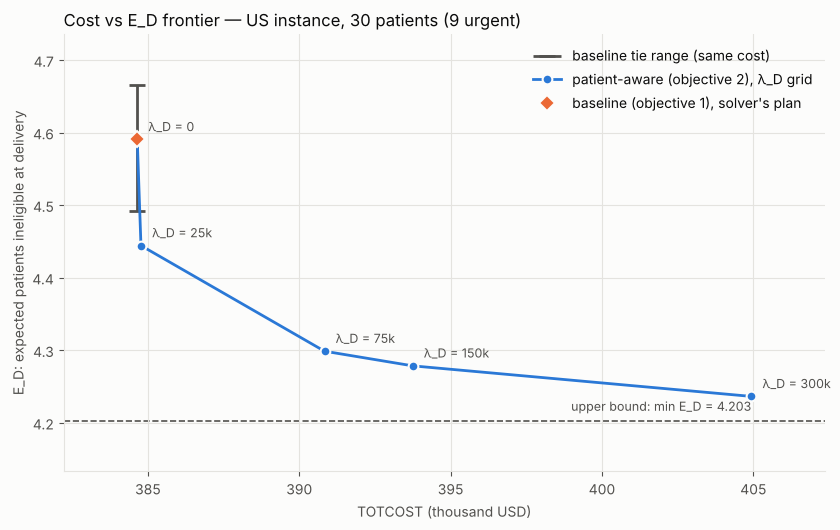

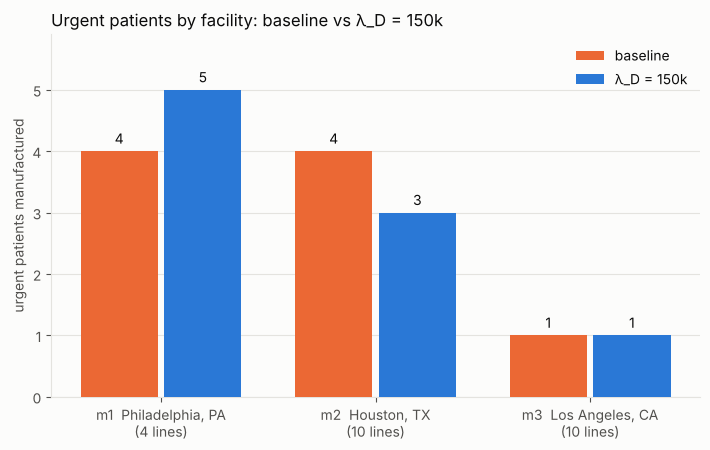

In [13]:
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10})

# --- Cost vs E_D frontier
S = summ.set_index("run")
fig, ax = plt.subplots(figsize=(8.6, 5.4))
k = 1e3
lam_pts = S.loc[[LAM_NAME[l] for l, _ in LAMBDA_GRID]]
ax.axhline(ED_MIN, color=INK2, lw=1.2, ls="--", zorder=1)
ax.annotate(f"upper bound: min E_D = {ED_MIN:.3f}", (lam_pts.TOTCOST.max() / k, ED_MIN), xytext=(0, 5),
            textcoords="offset points", ha="right", va="bottom", color=INK2, fontsize=9)
ax.plot([C_STAR / k] * 2, [tie_best["E_D"], tie_worst["E_D"]], color=INK2, lw=2, solid_capstyle="butt",
        marker="_", ms=12, mew=2, zorder=2, label="baseline tie range (same cost)")
ax.plot(lam_pts.TOTCOST / k, lam_pts.E_D, color=BLUE, lw=2, marker="o", ms=7, mec=SURF, mew=1.5, zorder=3,
        label="patient-aware (objective 2), λ_D grid")
ax.plot([C_STAR / k], [ED_BASE], ls="none", marker="D", ms=8, color=ORANGE, mec=SURF, mew=1.5, zorder=4,
        label="baseline (objective 1), solver's plan")
seen = set()
for l, _ in LAMBDA_GRID:
    r = S.loc[LAM_NAME[l]]
    key = (round(r.TOTCOST, 2), round(r.E_D, 6))
    if key in seen:
        continue
    same = [f"{int(l2 / 1000)}k" if l2 else "0" for l2, _ in LAMBDA_GRID
            if (round(S.loc[LAM_NAME[l2]].TOTCOST, 2), round(S.loc[LAM_NAME[l2]].E_D, 6)) == key]
    seen.add(key)
    ax.annotate("λ_D = " + ", ".join(same), (r.TOTCOST / k, r.E_D), xytext=(8, 6), textcoords="offset points",
                fontsize=9, color=INK2)
ax.set_xlabel("TOTCOST (thousand USD)")
ax.set_ylabel("E_D: expected patients ineligible at delivery")
ax.set_title("Cost vs E_D frontier — US instance, 30 patients (9 urgent)", loc="left", fontsize=12, color=INK)
ax.margins(x=0.12, y=0.15)
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_cost_vs_ED_frontier.png"), dpi=200)
plt.show()

# --- Urgent patients by facility: baseline vs lambda_D = 150k
fig, ax = plt.subplots(figsize=(7.2, 4.6))
x = np.arange(len(M))
w = 0.36
for i, (nm, col, lab) in enumerate([("baseline", ORANGE, "baseline"), (lam150, BLUE, "λ_D = 150k")]):
    vals = [S.loc[nm, f"urgent_{f}"] for f in M]
    bars = ax.bar(x + (i - 0.5) * (w + 0.03), vals, w, color=col, label=lab, zorder=3)
    for b, val in zip(bars, vals):
        ax.annotate(f"{int(val)}", (b.get_x() + b.get_width() / 2, val), xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", color=INK, fontsize=10)
ax.set_xticks(x, [f"{f}  {M_CITY[f]}\n({FCAP[f]} lines)" for f in M])
ax.set_ylabel("urgent patients manufactured")
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
ax.set_title("Urgent patients by facility: baseline vs λ_D = 150k", loc="left", fontsize=12, color=INK)
ax.legend(frameon=False)
ax.margins(y=0.18)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_urgent_by_facility.png"), dpi=200)
plt.show()

## 7. Verification

In [14]:
all_ok = True
for nm, lst in VERIF.items():
    print(f"\n--- {nm}")
    for chk, ok in lst:
        all_ok &= bool(ok)
        print(f"  [{'PASS' if ok else 'FAIL'}] {chk}")

print("\n--- cross-run and data checks")
lam0 = S.loc[LAM_NAME[0.0]]
cross = [
    (f"lambda_D = 0 run reproduces baseline cost C* ({lam0.TOTCOST:,.2f} vs {C_STAR:,.2f})", abs(lam0.TOTCOST - C_STAR) <= 1e-6 * C_STAR),
    ("tie-range runs stay within C*(1+1e-6)", tie_best["TOTCOST"] <= CAP + 1e-6 and tie_worst["TOTCOST"] <= CAP + 1e-6),
    ("tie range brackets the baseline E_D", tie_best["E_D"] - 1e-6 <= ED_BASE <= tie_worst["E_D"] + 1e-6),
    ("E_D_min <= E_D of every run", all(ED_MIN <= e + 1e-6 for e in summ.E_D)),
    ("E_D non-increasing and TOTCOST non-decreasing in lambda_D",
     all(np.diff(lam_pts.E_D.values) <= 1e-6) and all(np.diff(lam_pts.TOTCOST.values) >= -1e-4)),
] + checks
for chk, ok in cross:
    all_ok &= bool(ok)
    print(f"  [{'PASS' if ok else 'FAIL'}] {chk}")

verif_df = pd.DataFrame([(nm, chk, "PASS" if ok else "FAIL") for nm, lst in VERIF.items() for chk, ok in lst]
                        + [("cross-run / data", chk, "PASS" if ok else "FAIL") for chk, ok in cross],
                        columns=["run", "check", "result"])
verif_df.to_csv(os.path.join(OUT_DIR, "verification.csv"), index=False)
print(f"\nOVERALL: {'PASS' if all_ok else 'FAIL'}")
assert all_ok, "Verification failed"


--- baseline
  [PASS] one outbound shipment / one start / one delivery per patient
  [PASS] delivery hospital = paired hospital
  [PASS] same facility for outbound, arrival, start and return
  [PASS] start >= arrival day
  [PASS] capacity (17) respected for every facility and day
  [PASS] TRT <= 40 for all patients
  [PASS] TRT = T_LS + TT1 + W + T_MFE + T_QC + TT2 (recomputed from route/modes)
  [PASS] E_D from per-patient table = solver value (1e-6)
  [PASS] E_U from per-patient table = solver value (1e-6)
  [PASS] TOTCOST recomputed from table = solver value

--- tie_min_ED (best same-cost)
  [PASS] one outbound shipment / one start / one delivery per patient
  [PASS] delivery hospital = paired hospital
  [PASS] same facility for outbound, arrival, start and return
  [PASS] start >= arrival day
  [PASS] capacity (17) respected for every facility and day
  [PASS] TRT <= 40 for all patients
  [PASS] TRT = T_LS + TT1 + W + T_MFE + T_QC + TT2 (recomputed from route/modes)
  [PASS] E_D 